<a href="https://colab.research.google.com/github/Razaurrahmanbennett/CSET_343/blob/main/lab_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# If needed, uncomment and run:
# %pip install pandas numpy matplotlib seaborn scikit-learn requests

import warnings
warnings.filterwarnings("ignore")

import io
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, auc, roc_auc_score
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)


In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/dermatology/dermatology.data"

feature_names = [
    "erythema", "scaling", "definite_borders", "itching", "koebner_phenomenon",
    "polygonal_papules", "follicular_papules", "oral_mucosal_involvement",
    "knee_elbow_involvement", "scalp_involvement", "family_history",
    "melanin_incontinence", "eosinophils_infiltrate", "PNL_infiltrate",
    "fibrosis_papillary_dermis", "exocytosis", "acanthosis", "hyperkeratosis",
    "parakeratosis", "clubbing_rete_ridges", "elongation_rete_ridges",
    "thinning_suprapapillary_epidermis", "spongiform_pustule",
    "munro_microabcess", "focal_hypergranulosis", "disappearance_granular_layer",
    "vacuolisation_damage_basal_layer", "spongiosis", "saw_tooth_rete_ridges",
    "follicular_horn_plug", "perifollicular_parakeratosis",
    "inflammatory_mononuclear_infiltrate", "band_like_infiltrate", "age"
]
target_name = "class"

response = requests.get(DATA_URL, timeout=30)
response.raise_for_status()

df = pd.read_csv(
    io.StringIO(response.text),
    header=None,
    names=feature_names + [target_name],
    na_values=["?"],
    skipinitialspace=True
)

# Ensure every column is numeric; invalid values become NaN and are handled later.
df = df.apply(pd.to_numeric, errors="coerce")

print("Dataset shape:", df.shape)
display(df.head())
print("\nTarget classes:", sorted(df[target_name].dropna().unique()))

Dataset shape: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_elbow_involvement,scalp_involvement,family_history,melanin_incontinence,eosinophils_infiltrate,PNL_infiltrate,fibrosis_papillary_dermis,exocytosis,acanthosis,hyperkeratosis,parakeratosis,clubbing_rete_ridges,elongation_rete_ridges,thinning_suprapapillary_epidermis,spongiform_pustule,munro_microabcess,focal_hypergranulosis,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_rete_ridges,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_mononuclear_infiltrate,band_like_infiltrate,age,class
0,2,2,0,3,0,0,0,0,1,0,0,0,0,0,0,3,2,0,0,0,0,0,0,0,0,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,1,0,0,1,0,1,2,0,2,2,2,2,2,1,0,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,0,1,0,0,0,1,2,0,2,0,0,0,0,0,2,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,0,0,0,3,0,0,2,0,3,2,2,2,2,0,0,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,0,1,0,0,0,1,2,0,0,0,0,0,0,0,2,2,3,2,3,0,0,2,3,45.0,3



Target classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


In [3]:
print("Dataset information:")
df.info()

print("\nSummary statistics (features):")
display(df[feature_names].describe().T)

print("\nMedian for each feature:")
display(df[feature_names].median().rename("median").to_frame())

print("\nMissing values per column:")
missing_counts = df.isna().sum()
display(missing_counts[missing_counts > 0].sort_values(ascending=False).to_frame("missing_count"))

print("\nDuplicate rows:", int(df.duplicated().sum()))
print("\nClass counts:")
display(df[target_name].value_counts(dropna=False).sort_index().to_frame("count"))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 366 entries, 0 to 365
Data columns (total 35 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   erythema                             366 non-null    int64  
 1   scaling                              366 non-null    int64  
 2   definite_borders                     366 non-null    int64  
 3   itching                              366 non-null    int64  
 4   koebner_phenomenon                   366 non-null    int64  
 5   polygonal_papules                    366 non-null    int64  
 6   follicular_papules                   366 non-null    int64  
 7   oral_mucosal_involvement             366 non-null    int64  
 8   knee_elbow_involvement               366 non-null    int64  
 9   scalp_involvement                    366 non-null    int64  
 10  family_history                       366 non-null    int64  
 11  melanin_inc

,count,mean,std,min,25%,50%,75%,max
erythema,366.0,2.068306,0.664753,0.0,2.0,2.0,2.00,3.0
scaling,366.0,1.795082,0.701527,0.0,1.0,2.0,2.00,3.0
definite_borders,366.0,1.549180,0.907525,0.0,1.0,2.0,2.00,3.0
itching,366.0,1.366120,1.138299,0.0,0.0,1.0,2.00,3.0
koebner_phenomenon,366.0,0.633880,0.908016,0.0,0.0,0.0,1.00,3.0
polygonal_papules,366.0,0.448087,0.957327,0.0,0.0,0.0,0.00,3.0
follicular_papules,366.0,0.166667,0.570588,0.0,0.0,0.0,0.00,3.0
oral_mucosal_involvement,366.0,0.377049,0.834147,0.0,0.0,0.0,0.00,3.0
knee_elbow_involvement,366.0,0.614754,0.982979,0.0,0.0,0.0,1.00,3.0
scalp_involvement,366.0,0.519126,0.905639,0.0,0.0,0.0,1.00,3.0



Median for each feature:


,median
erythema,2.0
scaling,2.0
definite_borders,2.0
itching,1.0
koebner_phenomenon,0.0
polygonal_papules,0.0
follicular_papules,0.0
oral_mucosal_involvement,0.0
knee_elbow_involvement,0.0
scalp_involvement,0.0



Missing values per column:


,missing_count
age,8



Duplicate rows: 0

Class counts:


,count
class,
1,112
2,61
3,72
4,49
5,52
6,20


In [4]:
# Remove exact duplicates, if any.
df = df.drop_duplicates().copy()

# A row without a target label cannot be used for supervised classification.
df = df.dropna(subset=[target_name]).copy()
df[target_name] = df[target_name].astype(int)

# Confirm expected class labels and show remaining missing values.
print("Shape after removing duplicates / missing target:", df.shape)
print("Classes:", sorted(df[target_name].unique()))
print("Missing feature values:", int(df[feature_names].isna().sum().sum()))
display(df[feature_names].isna().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))

Shape after removing duplicates / missing target: (366, 35)
Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Missing feature values: 8


,missing_count
age,8
erythema,0
scaling,0
definite_borders,0
koebner_phenomenon,0
itching,0
follicular_papules,0
oral_mucosal_involvement,0
knee_elbow_involvement,0
polygonal_papules,0


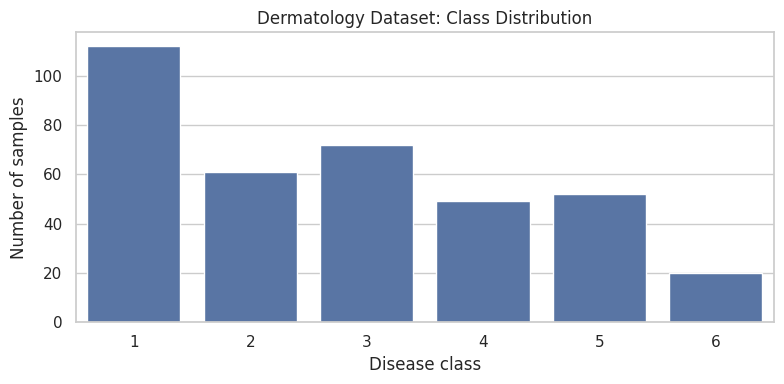

Class proportions (%):


,percentage
class,
1,30.60
2,16.67
3,19.67
4,13.39
5,14.21
6,5.46


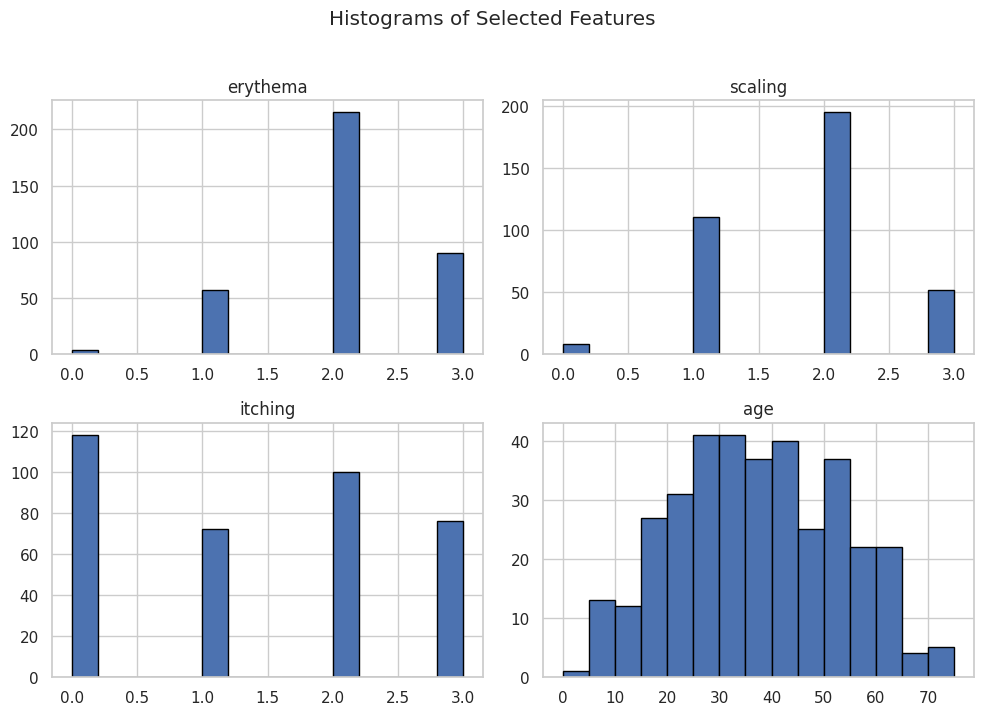

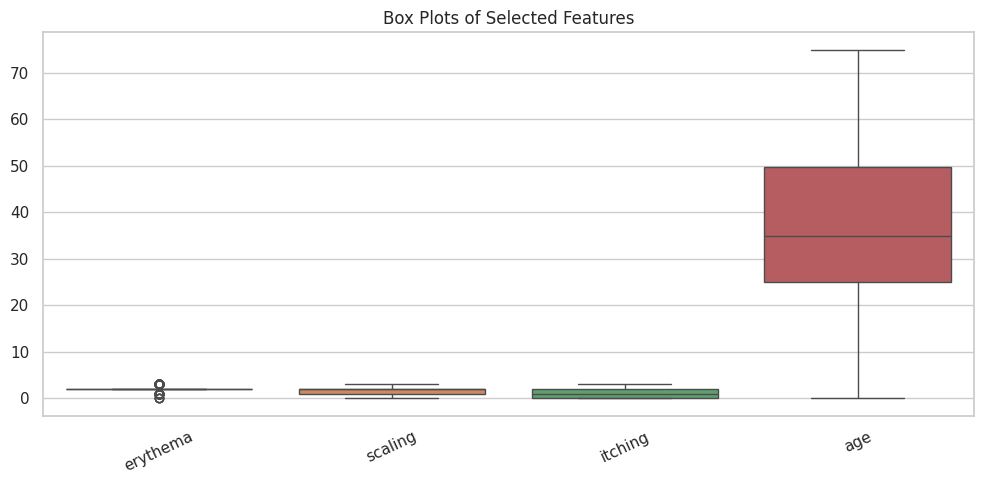

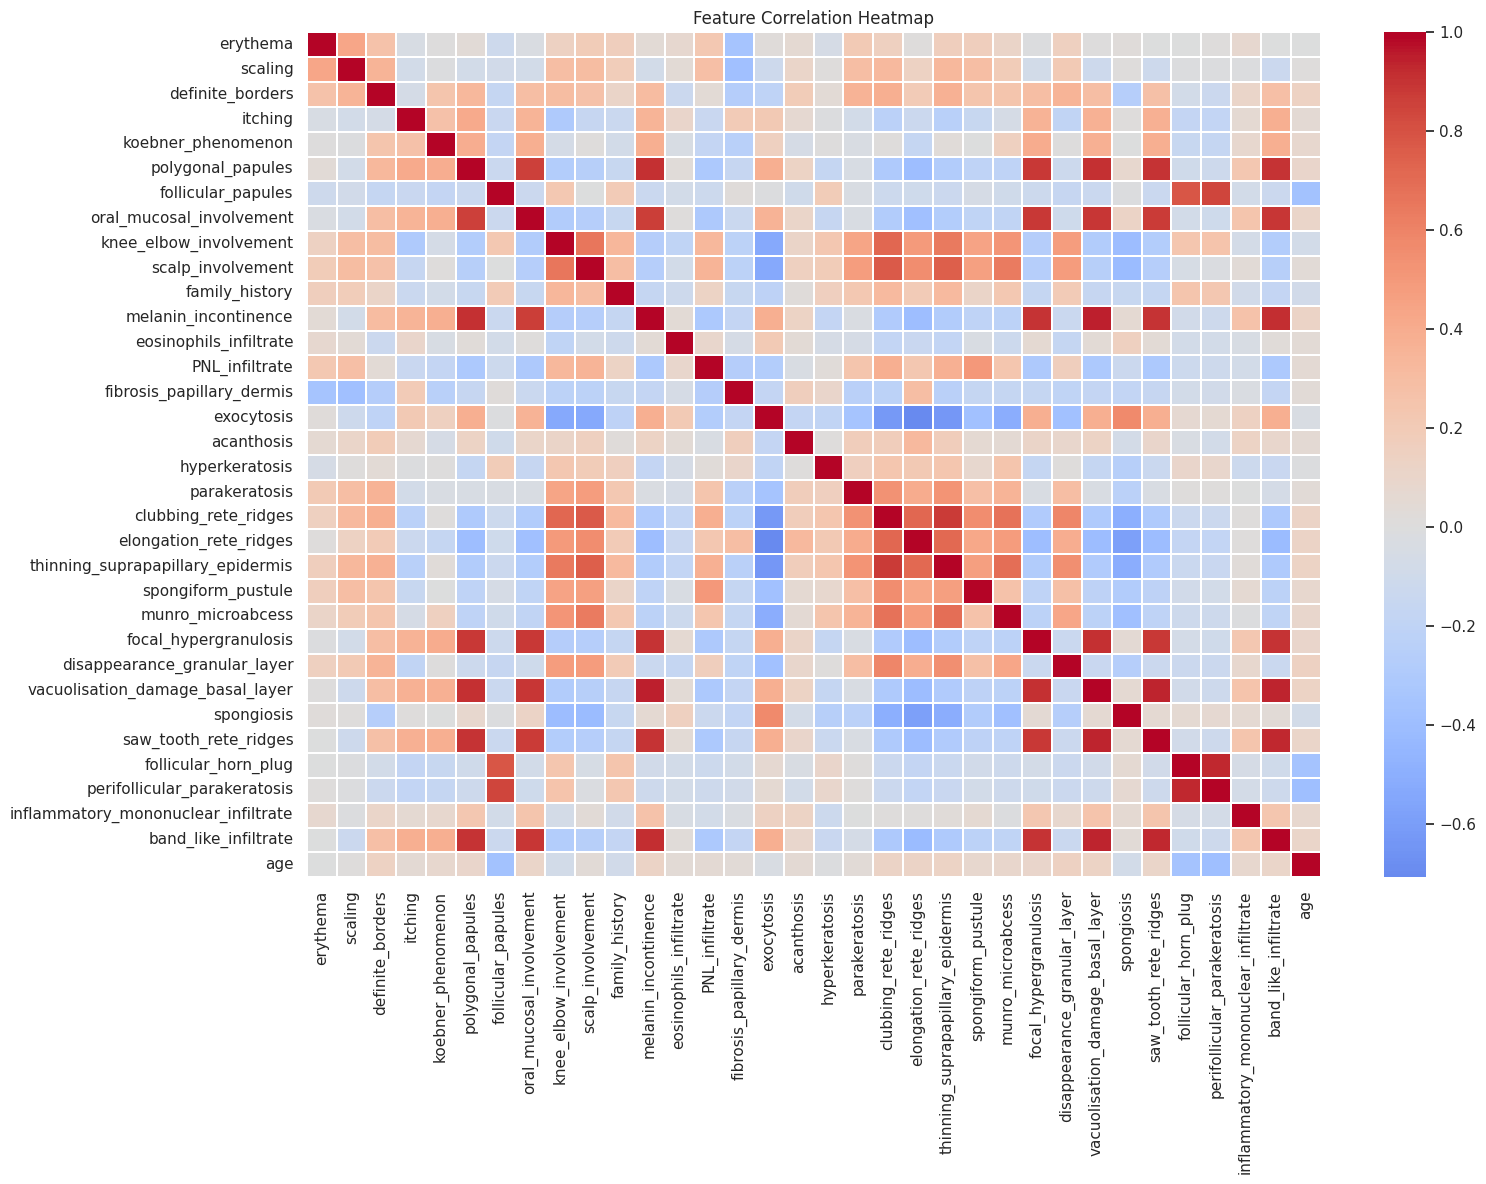

In [5]:
# Class distribution
class_counts = df[target_name].value_counts().sort_index()
plt.figure(figsize=(8, 4))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values)
plt.title("Dermatology Dataset: Class Distribution")
plt.xlabel("Disease class")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

print("Class proportions (%):")
display((class_counts / class_counts.sum() * 100).round(2).rename("percentage").to_frame())

# Histograms for selected features
selected_features = ["erythema", "scaling", "itching", "age"]
df[selected_features].hist(figsize=(10, 7), bins=15, edgecolor="black")
plt.suptitle("Histograms of Selected Features", y=1.02)
plt.tight_layout()
plt.show()

# Box plots for selected features
plt.figure(figsize=(10, 5))
sns.boxplot(data=df[selected_features])
plt.title("Box Plots of Selected Features")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Correlation heatmap
plt.figure(figsize=(16, 12))
sns.heatmap(df[feature_names].corr(), cmap="coolwarm", center=0, linewidths=0.15)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [6]:
outlier_rows = []
for col in feature_names:
    series = df[col].dropna()
    if series.empty:
        continue
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = int(((series < lower) | (series > upper)).sum())
    outlier_rows.append({
        "feature": col, "lower_bound": lower, "upper_bound": upper,
        "potential_outlier_count": count
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values(
    "potential_outlier_count", ascending=False
)
display(outlier_summary.head(15))

print("Interpretation: IQR flags are potential outliers, not proof of errors.")
print("No observations are removed solely because they fall outside the IQR range.")

,feature,lower_bound,upper_bound,potential_outlier_count
16,acanthosis,2.0,2.0,156
0,erythema,2.0,2.0,151
23,munro_microabcess,0.0,0.0,80
32,band_like_infiltrate,0.0,0.0,77
28,saw_tooth_rete_ridges,0.0,0.0,72
26,vacuolisation_damage_basal_layer,0.0,0.0,72
24,focal_hypergranulosis,0.0,0.0,71
22,spongiform_pustule,0.0,0.0,70
11,melanin_incontinence,0.0,0.0,70
5,polygonal_papules,0.0,0.0,69


Interpretation: IQR flags are potential outliers, not proof of errors.
No observations are removed solely because they fall outside the IQR range.


In [7]:
X = df[feature_names].copy()
y = df[target_name].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nTraining class proportions:")
display((y_train.value_counts(normalize=True).sort_index() * 100).round(2).to_frame("train_percent"))
print("\nTest class proportions:")
display((y_test.value_counts(normalize=True).sort_index() * 100).round(2).to_frame("test_percent"))

Training set: (292, 34)
Test set: (74, 34)

Training class proportions:


,train_percent
class,
1,30.48
2,16.78
3,19.52
4,13.36
5,14.38
6,5.48



Test class proportions:


,test_percent
class,
1,31.08
2,16.22
3,20.27
4,13.51
5,13.51
6,5.41


In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Support Vector Machine": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=400, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ])
}

fitted_models = {}
predictions = {}
probabilities = {}
results = []

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    fitted_models[name] = pipeline
    predictions[name] = y_pred

    # All selected estimators support predict_proba in this configuration.
    y_prob = pipeline.predict_proba(X_test)
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
        "ROC-AUC (OvR macro)": roc_auc_score(
            y_test, y_prob, labels=fitted_models[name].named_steps["model"].classes_,
            multi_class="ovr", average="macro"
        )
    })

results_df = pd.DataFrame(results).sort_values(
    by=["F1-score (macro)", "ROC-AUC (OvR macro)"], ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),F1-score (weighted),ROC-AUC (OvR macro)
0,Support Vector Machine,0.9730,0.9722,0.9722,0.9697,0.9730,0.9981
1,Logistic Regression,0.9595,0.9615,0.9611,0.9574,0.9606,0.9993
2,Random Forest,0.9595,0.9545,0.9556,0.9545,0.9595,0.9984
3,Gradient Boosting,0.9324,0.9062,0.9250,0.9125,0.9309,0.9949
4,K-Nearest Neighbors,0.9054,0.9071,0.9094,0.9034,0.9081,0.9863



Logistic Regression
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        23
     Class 2       1.00      0.83      0.91        12
     Class 3       1.00      0.93      0.97        15
     Class 4       0.77      1.00      0.87        10
     Class 5       1.00      1.00      1.00        10
     Class 6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.97      0.96      0.96        74



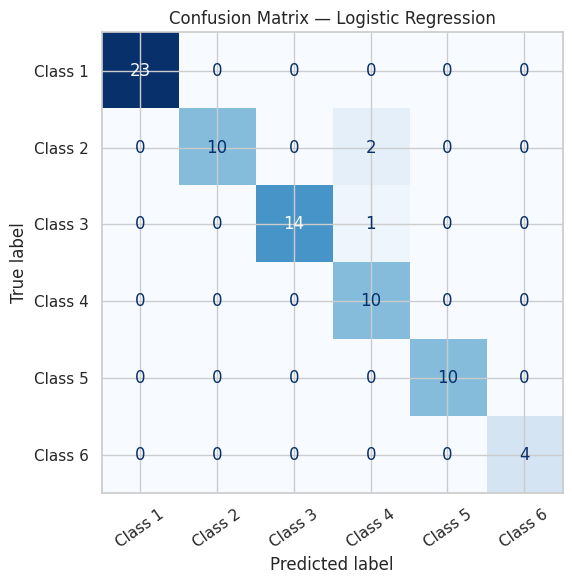


K-Nearest Neighbors
              precision    recall  f1-score   support

     Class 1       1.00      0.96      0.98        23
     Class 2       0.80      0.67      0.73        12
     Class 3       1.00      0.93      0.97        15
     Class 4       0.64      0.90      0.75        10
     Class 5       1.00      1.00      1.00        10
     Class 6       1.00      1.00      1.00         4

    accuracy                           0.91        74
   macro avg       0.91      0.91      0.90        74
weighted avg       0.92      0.91      0.91        74



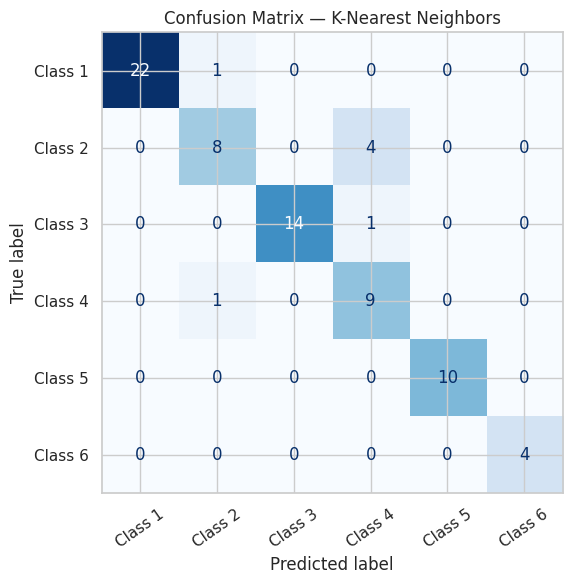


Support Vector Machine
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        23
     Class 2       1.00      0.83      0.91        12
     Class 3       1.00      1.00      1.00        15
     Class 4       0.83      1.00      0.91        10
     Class 5       1.00      1.00      1.00        10
     Class 6       1.00      1.00      1.00         4

    accuracy                           0.97        74
   macro avg       0.97      0.97      0.97        74
weighted avg       0.98      0.97      0.97        74



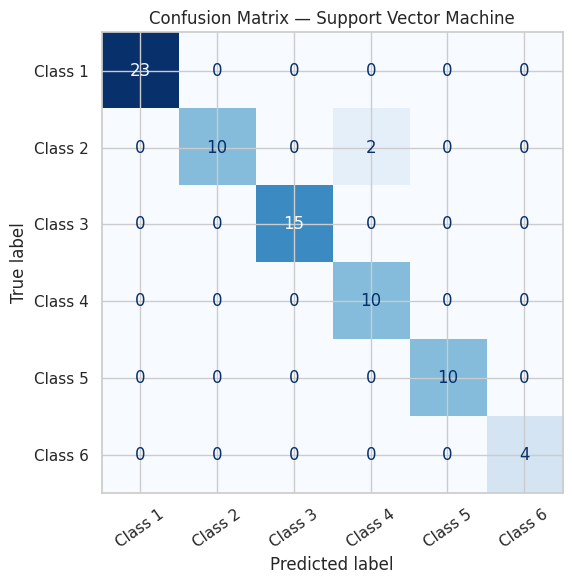


Random Forest
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        23
     Class 2       0.91      0.83      0.87        12
     Class 3       1.00      1.00      1.00        15
     Class 4       0.82      0.90      0.86        10
     Class 5       1.00      1.00      1.00        10
     Class 6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.95      0.96      0.95        74
weighted avg       0.96      0.96      0.96        74



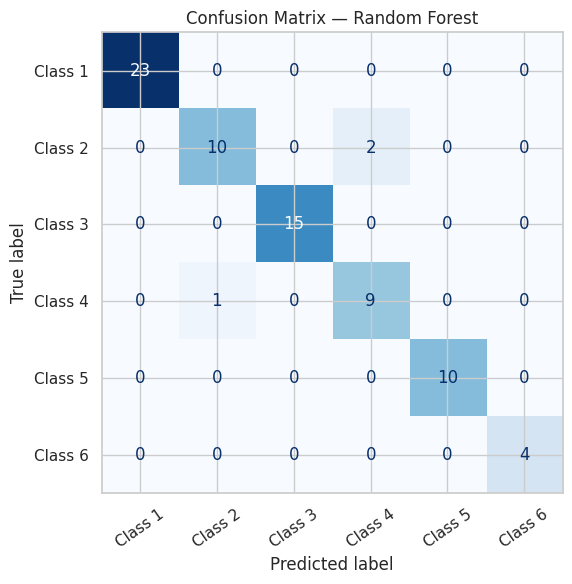


Gradient Boosting
              precision    recall  f1-score   support

     Class 1       1.00      1.00      1.00        23
     Class 2       0.90      0.75      0.82        12
     Class 3       0.94      1.00      0.97        15
     Class 4       0.80      0.80      0.80        10
     Class 5       1.00      1.00      1.00        10
     Class 6       0.80      1.00      0.89         4

    accuracy                           0.93        74
   macro avg       0.91      0.92      0.91        74
weighted avg       0.93      0.93      0.93        74



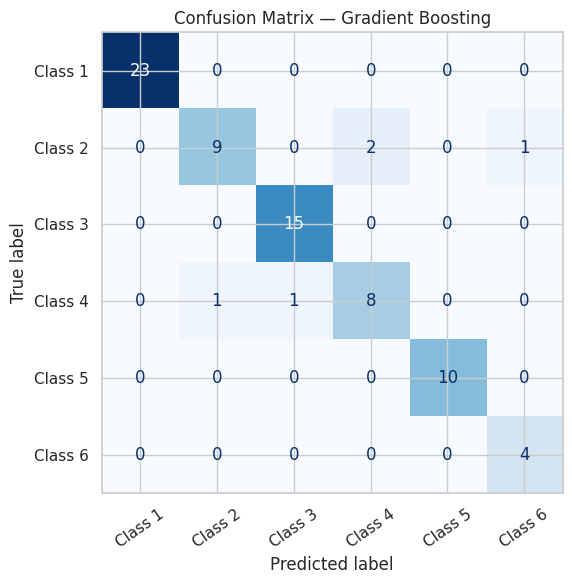

In [9]:
class_labels = sorted(y.unique())

for name, y_pred in predictions.items():
    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)
    print(classification_report(
        y_test, y_pred, labels=class_labels, zero_division=0,
        target_names=[f"Class {c}" for c in class_labels]
    ))

    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[f"Class {c}" for c in class_labels]
    )
    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set_title(f"Confusion Matrix — {name}")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

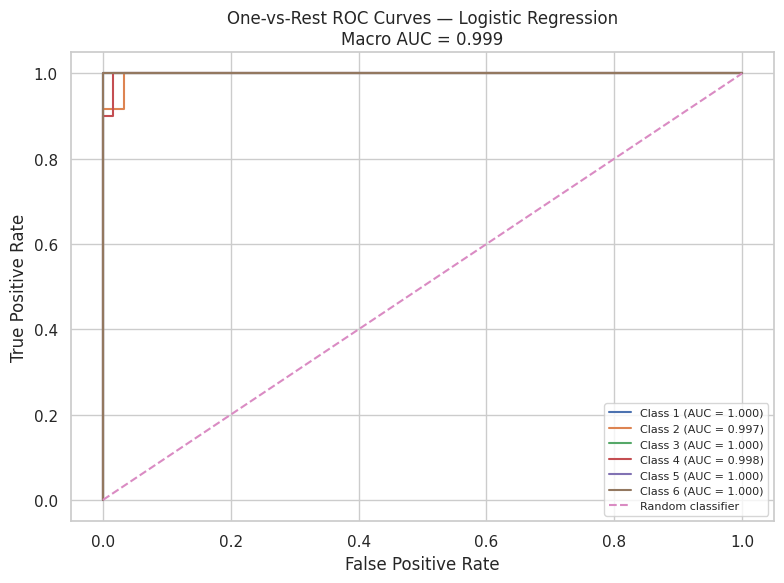

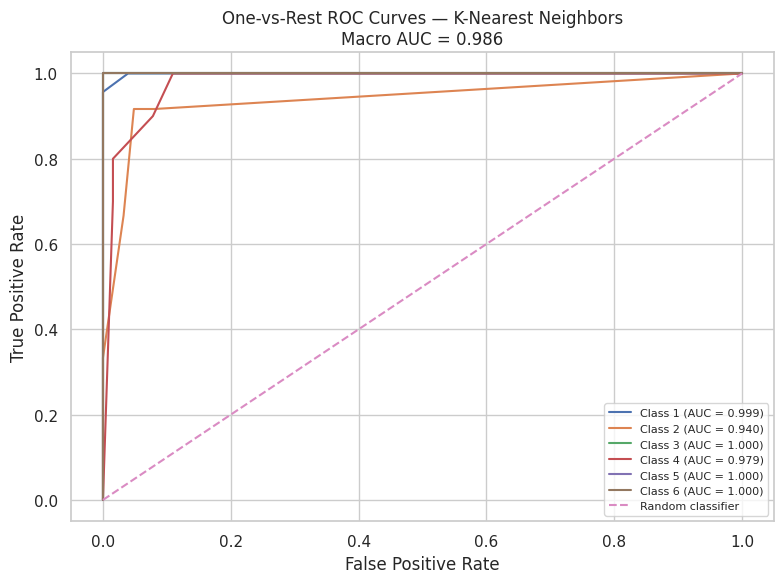

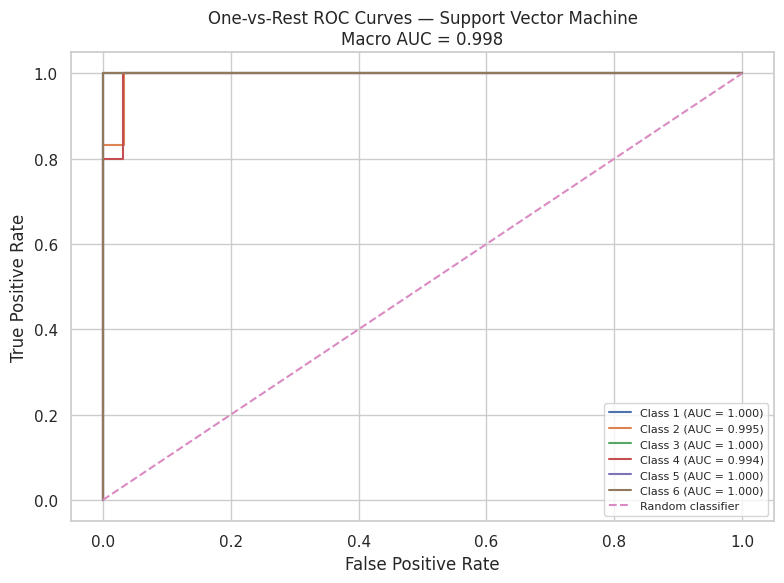

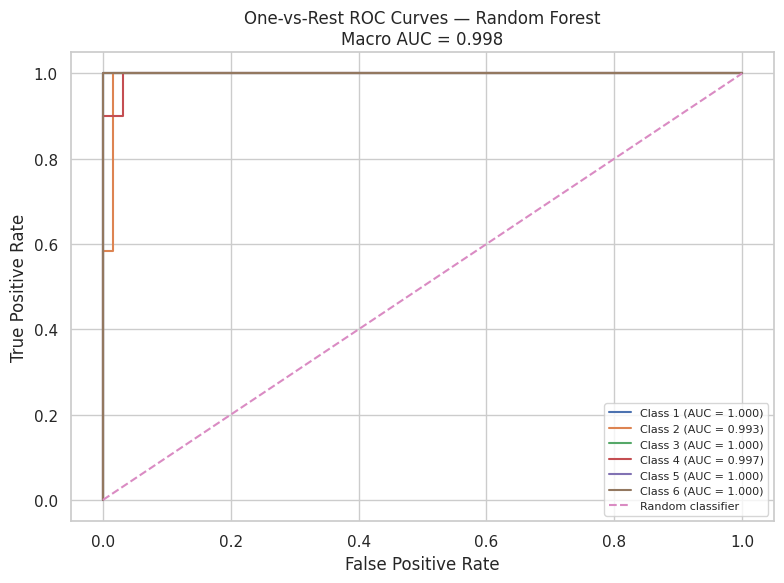

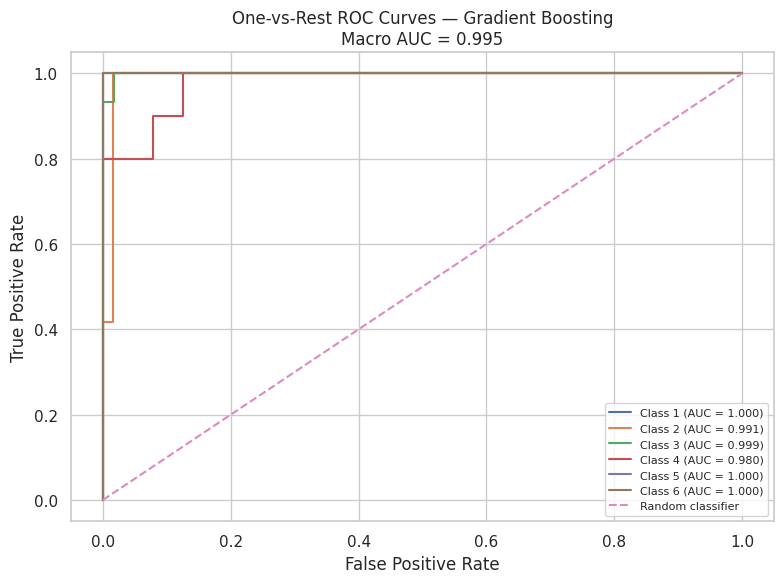

In [10]:
classes = np.array(class_labels)
y_test_bin = label_binarize(y_test, classes=classes)

for name, y_prob in probabilities.items():
    # probability columns follow the estimator's class order; here classes are 1..6.
    model_classes = fitted_models[name].named_steps["model"].classes_
    # Reorder probability columns to the same order as `classes`, if necessary.
    prob_df = pd.DataFrame(y_prob, columns=model_classes)
    y_prob_ordered = prob_df[classes].to_numpy()

    plt.figure(figsize=(8, 6))
    for idx, class_value in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_test_bin[:, idx], y_prob_ordered[:, idx])
        class_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"Class {class_value} (AUC = {class_auc:.3f})")

    plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
    macro_auc = roc_auc_score(
        y_test, y_prob_ordered, labels=classes, multi_class="ovr", average="macro"
    )
    plt.title(f"One-vs-Rest ROC Curves — {name}\nMacro AUC = {macro_auc:.3f}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right", fontsize=8)
    plt.tight_layout()
    plt.show()

Best model by macro F1-score (tie-breaker: macro ROC-AUC): Support Vector Machine
Model                  Support Vector Machine
Accuracy                             0.972973
Precision (macro)                    0.972222
Recall (macro)                       0.972222
F1-score (macro)                     0.969697
F1-score (weighted)                  0.972973
ROC-AUC (OvR macro)                  0.998062


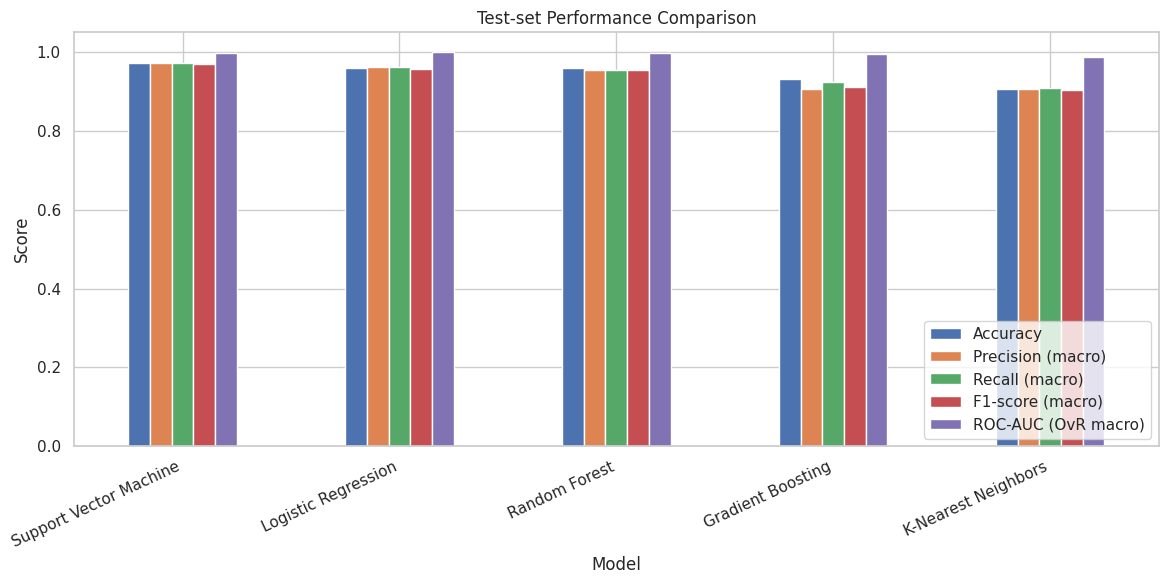

In [11]:
# The top model is selected by macro F1, then macro ROC-AUC as a tie-breaker.
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

print("Best model by macro F1-score (tie-breaker: macro ROC-AUC):", best_model_name)
print(results_df.iloc[0].to_string())

# Visual comparison
plot_df = results_df.set_index("Model")[[
    "Accuracy", "Precision (macro)", "Recall (macro)",
    "F1-score (macro)", "ROC-AUC (OvR macro)"
]]
plot_df.plot(kind="bar", figsize=(12, 6), ylim=(0, 1.05))
plt.title("Test-set Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [12]:
results_df.to_csv("dermatology_model_comparison.csv", index=False)
print("Saved: dermatology_model_comparison.csv")

Saved: dermatology_model_comparison.csv
